# Gradia.AI: Training and evaluation (v2)

Trains the lesion classifier on the clean, lesion-grouped split made by `PREPROCESS.ipynb`, then evaluates it **once** on the held-out test set.

**What changed from the first `TRAIN.ipynb`, and why**

| Before | Now | Why |
|---|---|---|
| Split by image | Split by lesion (from `PREPROCESS.ipynb`) | EDA: 39% of old validation images had a sibling photo in training |
| Train/val only | Train / val / **test** | Validation picks the epoch, so it can't also be the reported score |
| Train squashed images to a square | Train and test use the same geometry | The model was tested on a different shape than it learned |
| Best epoch by accuracy | Best epoch by **macro-F1** | Accuracy is 67% just by predicting "nevus" |
| Accuracy only | Per-class recall/F1, balanced accuracy, confusion matrix, AUC, confidence ranges | Shows how each class, especially melanoma, really does |
| Raw softmax scores | **Temperature scaling** | Makes "80%" mean roughly 80% correct |
| Weights `1/count` (58× range) | Weights `1/√count` | Still favours rare classes, but trains more stably |
| 20 epochs, last weights | 30 epochs, **EMA** weights, **label smoothing** | Smoother, better-generalising model |
| One view per image | Optional **test-time augmentation** (8 views) | Usually a few points better; reported separately from the single-view number the app uses |

**About the old 88.67%.** It was measured on a validation set where 39% of images had a sibling photo of the same lesion in training, and that same set chose the best epoch. The numbers here come from unseen lesions, so they are honest but **not directly comparable**. Compare against the always-"nevus" baseline and per-class recall instead.

**Two experiments, same split.** Run once with `EXPERIMENT = "image"` (works with the current backend as-is), then once with `EXPERIMENT = "fusion"` (image + age, sex, body site). The last cell compares them.

**Hardware.** Built for a laptop RTX 3050 (mixed precision, automatic batch-size fallback if the GPU runs out of memory). Also runs on Colab.

## 0. Setup

In [6]:
import os, sys, json, time, math, random, importlib, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import (f1_score, balanced_accuracy_score, accuracy_score, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score)

IN_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in globals() else False

# ── Experiment ───────────────────────────────────────────────────────────────
EXPERIMENT = os.environ.get("GRADIA_EXPERIMENT", "image")   # "image" or "fusion"

# ── Paths ────────────────────────────────────────────────────────────────────
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/gradia_data"
else:
    DATA_DIR = os.environ.get("GRADIA_DATA_DIR", r"C:\Users\krish.LAPTOP-3EPNQNP7\Documents\gradia_data")
IMAGE_DIR = os.path.join(DATA_DIR, "images_256")
RUN_DIR   = os.path.join(DATA_DIR, "runs", EXPERIMENT)
os.makedirs(RUN_DIR, exist_ok=True)

# ── Hyperparameters ──────────────────────────────────────────────────────────
CFG = {
    "experiment": EXPERIMENT,
    "epochs": int(os.environ.get("GRADIA_EPOCHS", 30)),
    "batch_size": int(os.environ.get("GRADIA_BATCH", 32)),   # halved automatically if the GPU runs out of memory
    "lr_backbone": 1e-4,          # pretrained layers: small steps
    "lr_head": 1e-3,              # new layers: larger steps
    "weight_decay": 1e-4,         # AdamW (decoupled weight decay)
    "warmup_epochs": 1,
    "early_stop_patience": 10,    # stop if the selection metric doesn't improve for this many epochs
    "select_metric": "macro_f1",  # "macro_f1" (fair to rare classes) or "acc" (overall accuracy)
    "label_smoothing": 0.1,       # targets 0.9 / 0.1 spread instead of hard 1 / 0: less over-confidence
    "ema_decay": 0.999,           # exponential moving average of the weights (0 = off)
    "tta": True,                  # also evaluate with 8 rotations/flips averaged
    "class_weighting": "inv_sqrt",  # "inv_sqrt", "inv" (old notebook) or "none"
    "image_size": 224,
    "resize_short": 256,
    "seed": 42,
    "pretrained": os.environ.get("GRADIA_NO_PRETRAINED") != "1",
    "num_workers": int(os.environ.get("GRADIA_WORKERS", 2 if IN_COLAB else 4)),
    "debug_subset": int(os.environ.get("GRADIA_SUBSET", 0)),   # 0 = use all data
}

# ── Reproducibility ──────────────────────────────────────────────────────────
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])
torch.backends.cudnn.benchmark = True   # faster convolutions; tiny run-to-run differences remain

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
print("PyTorch", torch.__version__, "| device:", DEVICE)
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | {p.total_memory / 1024**3:.1f} GB")
else:
    print("WARNING: no GPU found. Training will be very slow. See the note in the README cell.")
print("Data:", DATA_DIR, "| exists:", os.path.isdir(DATA_DIR))
print("Run folder:", RUN_DIR)
print(json.dumps(CFG, indent=2))

PyTorch 2.14.1+cu130 | device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU | 4.0 GB
Data: C:\Users\krish.LAPTOP-3EPNQNP7\Documents\gradia_data | exists: True
Run folder: C:\Users\krish.LAPTOP-3EPNQNP7\Documents\gradia_data\runs\image
{
  "experiment": "image",
  "epochs": 30,
  "batch_size": 32,
  "lr_backbone": 0.0001,
  "lr_head": 0.001,
  "weight_decay": 0.0001,
  "warmup_epochs": 1,
  "early_stop_patience": 10,
  "select_metric": "macro_f1",
  "label_smoothing": 0.1,
  "ema_decay": 0.999,
  "tta": true,
  "class_weighting": "inv_sqrt",
  "image_size": 224,
  "resize_short": 256,
  "seed": 42,
  "pretrained": true,
  "num_workers": 4,
  "debug_subset": 0
}


### If it says `device: cpu` on your laptop

Your PyTorch is the CPU-only build (the default from plain `pip install torch` on Windows). Install the CUDA build in your venv using the command from **pytorch.org → Get Started** (choose Windows, Pip, Python, CUDA), then restart the kernel. Check with:

`python -c "import torch; print(torch.cuda.is_available())"`  → should print `True`.

## 1. Shared code module

The dataset, transforms, metadata encoding and model live in a small `.py` file written next to the data. Two reasons:

1. **Windows:** parallel data loading (`num_workers > 0`) can't use classes defined inside a notebook, but it can import them from a file.
2. **One source of truth:** `encode_meta` and the transforms here are exactly what `gradia-backend/inference.py` must copy later.

In [7]:
UTILS_CODE = r"""
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms, models

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


class RandomRotate90:
    # Rotates by 0, 90, 180 or 270 degrees. Lossless: no black corners, no interpolation.
    # Together with a horizontal flip this covers all 8 orientations a lesion photo can have.
    OPS = [None, Image.Transpose.ROTATE_90, Image.Transpose.ROTATE_180, Image.Transpose.ROTATE_270]
    def __call__(self, img):
        op = self.OPS[int(torch.randint(4, (1,)))]   # torch RNG: seeded correctly per DataLoader worker
        return img if op is None else img.transpose(op)


def build_transforms(train, resize_short=256, size=224):
    if train:
        return transforms.Compose([
            transforms.Resize(resize_short),           # same geometry as inference: keep proportions
            RandomRotate90(),
            transforms.RandomCrop(size),               # random position (inference uses the centre)
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.02),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])
    return transforms.Compose([                        # identical to PREPROCESS in inference.py
        transforms.Resize(resize_short),
        transforms.CenterCrop(size),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])


def meta_size(vocab):
    return 2 + len(vocab["sex"]) + len(vocab["localization"])


def encode_meta(age_filled, age_missing, sex, site, vocab):
    # [standardised age, age_missing, one-hot sex, one-hot site]. inference.py must use this exact layout.
    v = np.zeros(meta_size(vocab), dtype=np.float32)
    v[0] = (float(age_filled) - vocab["age_mean_train"]) / vocab["age_std_train"]
    v[1] = float(age_missing)
    sexes, sites = vocab["sex"], vocab["localization"]
    v[2 + (sexes.index(sex) if sex in sexes else sexes.index("unknown"))] = 1.0
    v[2 + len(sexes) + (sites.index(site) if site in sites else sites.index("unknown"))] = 1.0
    return v


class HAMDataset(Dataset):
    def __init__(self, frame, image_dir, transform, vocab=None):
        self.df = frame.reset_index(drop=True)
        self.image_dir, self.transform, self.vocab = image_dir, transform, vocab

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        with Image.open(f"{self.image_dir}/{r['image_id']}.jpg") as im:
            x = self.transform(im.convert("RGB"))
        if self.vocab is not None:
            m = torch.from_numpy(encode_meta(r["age_filled"], r["age_missing"], r["sex"], r["localization"], self.vocab))
        else:
            m = torch.zeros(0)
        return x, m, int(r["label"])


class GradiaFusion(nn.Module):
    # Image features (2048) + metadata features (32) -> 7 classes
    def __init__(self, n_meta, n_classes=7, pretrained=True):
        super().__init__()
        w = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        self.backbone = models.resnet50(weights=w)
        self.backbone.fc = nn.Identity()
        self.meta = nn.Sequential(nn.Linear(n_meta, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(2048 + 32, n_classes))

    def forward(self, x, m):
        return self.head(torch.cat([self.backbone(x), self.meta(m)], dim=1))


def build_model(kind, n_meta=0, n_classes=7, pretrained=True):
    if kind == "image":
        # Same architecture as gradia-backend/inference.py, so the weights load there unchanged
        w = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        model = models.resnet50(weights=w)
        model.fc = nn.Linear(model.fc.in_features, n_classes)
        return model
    if kind == "fusion":
        return GradiaFusion(n_meta, n_classes, pretrained)
    raise ValueError(kind)


def forward(model, kind, x, m):
    return model(x) if kind == "image" else model(x, m)


def head_parameters(model, kind):
    return list(model.fc.parameters()) if kind == "image" else list(model.meta.parameters()) + list(model.head.parameters())
"""
with open(os.path.join(DATA_DIR, "gradia_train_utils.py"), "w", encoding="utf-8") as f:
    f.write(UTILS_CODE)
if DATA_DIR not in sys.path:
    sys.path.insert(0, DATA_DIR)
import gradia_train_utils as U
importlib.reload(U)
print("Wrote and imported", os.path.join(DATA_DIR, "gradia_train_utils.py"))

Wrote and imported C:\Users\krish.LAPTOP-3EPNQNP7\Documents\gradia_data\gradia_train_utils.py


## 2. Load the clean dataset

In [8]:
df = pd.read_csv(os.path.join(DATA_DIR, "ham10000_clean.csv"))
CLASSES = json.load(open(os.path.join(DATA_DIR, "classes.json")))
VOCAB = json.load(open(os.path.join(DATA_DIR, "metadata_vocab.json")))
N_CLASSES = len(CLASSES)
MEL = CLASSES.index("MEL")

missing = [i for i in df["image_id"] if not os.path.exists(f"{IMAGE_DIR}/{i}.jpg")]
assert not missing, f"{len(missing)} resized images missing, e.g. {missing[:3]}. Re-run PREPROCESS.ipynb."

if CFG["debug_subset"]:
    df = df.sample(frac=1, random_state=1).groupby("split").head(CFG["debug_subset"]).reset_index(drop=True)
    print(f"DEBUG: using a subset of {len(df)} images")

train_df, val_df, test_df = (df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"])
print({"train": len(train_df), "val": len(val_df), "test": len(test_df)}, "| classes:", CLASSES)
print("Train images per class:", train_df["dx"].str.upper().value_counts().reindex(CLASSES).to_dict())

{'train': 7153, 'val': 1431, 'test': 1431} | classes: ['AKIEC', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'VASC']
Train images per class: {'AKIEC': 234, 'BCC': 366, 'BKL': 785, 'DF': 82, 'MEL': 795, 'NV': 4789, 'VASC': 102}


## 3. Data loaders, augmentation and class weights

**Augmentation (training only):** random 90° rotations and horizontal flips (lesions have no "right way up"), a random 224 crop from the proportion-preserving 256 resize, and mild colour jitter for camera differences. Validation and test use the exact inference preprocessing.

**Class weights:** `1/√count`, normalised to average 1. Rare classes still count more in the loss, without the 58× extremes of `1/count`.

Class weights: {'AKIEC': np.float64(1.109), 'BCC': np.float64(0.887), 'BKL': np.float64(0.605), 'DF': np.float64(1.873), 'MEL': np.float64(0.602), 'NV': np.float64(0.245), 'VASC': np.float64(1.679)}


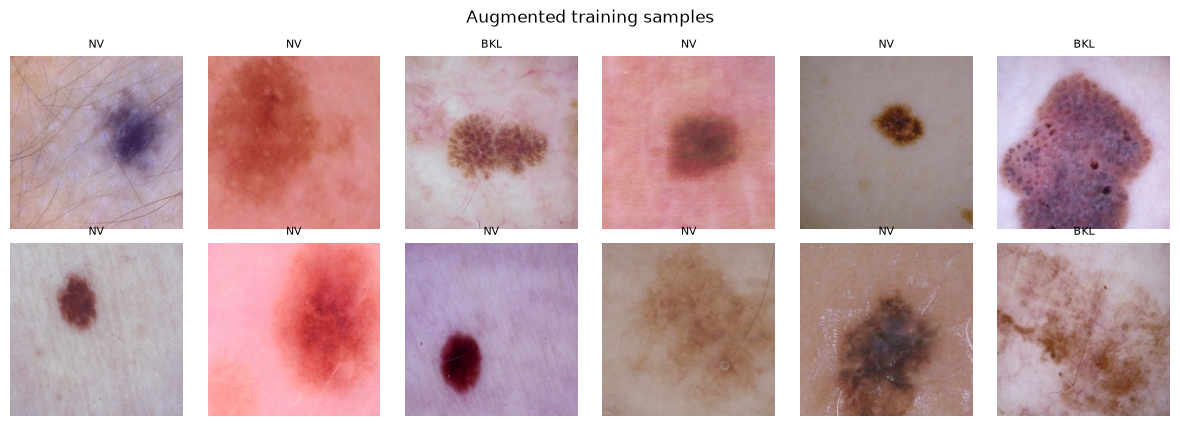

In [9]:
use_meta = EXPERIMENT == "fusion"
vocab_for_ds = VOCAB if use_meta else None
N_META = U.meta_size(VOCAB) if use_meta else 0

train_ds = U.HAMDataset(train_df, IMAGE_DIR, U.build_transforms(True,  CFG["resize_short"], CFG["image_size"]), vocab_for_ds)
val_ds   = U.HAMDataset(val_df,   IMAGE_DIR, U.build_transforms(False, CFG["resize_short"], CFG["image_size"]), vocab_for_ds)
test_ds  = U.HAMDataset(test_df,  IMAGE_DIR, U.build_transforms(False, CFG["resize_short"], CFG["image_size"]), vocab_for_ds)

def make_loader(ds, shuffle, bs):
    nw = CFG["num_workers"]
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=nw, pin_memory=DEVICE == "cuda",
                      persistent_workers=nw > 0, drop_last=False)

counts = train_df["label"].value_counts().reindex(range(N_CLASSES)).fillna(0).values.astype(float)
counts = np.maximum(counts, 1)
if CFG["class_weighting"] == "inv_sqrt":
    w = 1 / np.sqrt(counts)
elif CFG["class_weighting"] == "inv":
    w = 1 / counts
else:
    w = np.ones_like(counts)
w = w / w.mean()
CLASS_WEIGHTS = torch.tensor(w, dtype=torch.float32)
print("Class weights:", dict(zip(CLASSES, np.round(w, 3))))

# Look at a few augmented training images (undo normalisation to display)
mean, std = np.array(U.IMAGENET_MEAN), np.array(U.IMAGENET_STD)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.3))
for ax, i in zip(axes.ravel(), np.random.choice(len(train_ds), 12, replace=False)):
    x, _, y = train_ds[i]
    ax.imshow(np.clip(x.permute(1, 2, 0).numpy() * std + mean, 0, 1)); ax.set_title(CLASSES[y], fontsize=8); ax.axis("off")
plt.suptitle("Augmented training samples"); plt.tight_layout()
plt.savefig(os.path.join(RUN_DIR, "augmented_samples.png"), dpi=110); plt.show()

## 4. Model, optimiser and schedule

- **Model:** ImageNet-pretrained ResNet-50, every layer fine-tuned. For `"image"` it is exactly the architecture `inference.py` loads.
- **Two learning rates:** pretrained layers move slowly (1e-4), the new classification layers faster (1e-3).
- **AdamW** with weight decay, **1 epoch warm-up** then **cosine decay**, updated every batch.
- **Label smoothing (0.1):** the target for the true class is 0.9 instead of 1.0, so the model is never pushed towards 100% certainty.
- **EMA:** a second copy of the weights that is a running average of recent training steps. It is less noisy than the raw weights, so it is the copy that gets evaluated and saved.
- **Mixed precision** on the GPU: faster and uses less memory.
- **Batch-size check:** tries one training step; if the GPU runs out of memory, halves the batch size and tries again.

In [10]:
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

seed_everything(CFG["seed"])
model = U.build_model(EXPERIMENT, N_META, N_CLASSES, CFG["pretrained"]).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model: {EXPERIMENT} | parameters: {n_params:,} (all trainable)")

criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE), label_smoothing=CFG["label_smoothing"])

def find_batch_size(start):
    bs = start
    while bs >= 4:
        try:
            x = torch.randn(bs, 3, CFG["image_size"], CFG["image_size"], device=DEVICE)
            m = torch.zeros(bs, N_META, device=DEVICE)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = U.forward(model, EXPERIMENT, x, m).float().mean()
            loss.backward(); model.zero_grad(set_to_none=True)
            del x, m, loss
            if DEVICE == "cuda": torch.cuda.empty_cache()
            return bs
        except torch.OutOfMemoryError:
            model.zero_grad(set_to_none=True); torch.cuda.empty_cache()
            print(f"Batch size {bs} doesn't fit in GPU memory, trying {bs // 2}")
            bs //= 2
    raise RuntimeError("Even batch size 4 doesn't fit")

BATCH = find_batch_size(CFG["batch_size"]) if DEVICE == "cuda" else CFG["batch_size"]
CFG["batch_size_used"] = BATCH
train_loader = make_loader(train_ds, True, BATCH)
val_loader   = make_loader(val_ds, False, BATCH * 2)
test_loader  = make_loader(test_ds, False, BATCH * 2)
print("Batch size:", BATCH, "| train batches per epoch:", len(train_loader))

head_ids = {id(p) for p in U.head_parameters(model, EXPERIMENT)}
optimizer = torch.optim.AdamW([
    {"params": [p for p in model.parameters() if id(p) not in head_ids], "lr": CFG["lr_backbone"]},
    {"params": [p for p in model.parameters() if id(p) in head_ids],     "lr": CFG["lr_head"]},
], weight_decay=CFG["weight_decay"])

steps_per_epoch = len(train_loader)
total_steps = CFG["epochs"] * steps_per_epoch
warmup_steps = CFG["warmup_epochs"] * steps_per_epoch
def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

USE_EMA = CFG["ema_decay"] > 0
ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(CFG["ema_decay"]), use_buffers=True) if USE_EMA else None
eval_net = lambda: ema.module if USE_EMA else model
print("EMA:", USE_EMA, "| label smoothing:", CFG["label_smoothing"], "| select best epoch by:", CFG["select_metric"])

Model: image | parameters: 23,522,375 (all trainable)
Batch size: 32 | train batches per epoch: 224
EMA: True | label smoothing: 0.1 | select best epoch by: macro_f1


## 5. Training

Each epoch: one pass over the training set, then the validation set is scored with the EMA weights. The checkpoint with the best **validation** `select_metric` is kept, and training stops early if it hasn't improved for `early_stop_patience` epochs.

Columns in the log: training loss and accuracy (on augmented images, so a bit pessimistic), then validation loss, accuracy, balanced accuracy (average recall over the 7 classes), macro-F1 and melanoma recall.

In [11]:
@torch.no_grad()
def predict(loader, net, tta=False):
    # Returns raw logits. With tta=True, averages the logits of 8 views: 4 rotations x (flipped or not).
    net.eval()
    all_logits, all_y = [], []
    for x, m, y in loader:
        x, m = x.to(DEVICE, non_blocking=True), m.to(DEVICE, non_blocking=True)
        views = [x] if not tta else [torch.rot90(v, k, dims=(2, 3)) for v in (x, torch.flip(x, dims=(3,))) for k in range(4)]
        out = 0
        for v in views:
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                out = out + U.forward(net, EXPERIMENT, v, m).float()
        all_logits.append((out / len(views)).cpu()); all_y.append(y)
    return torch.cat(all_logits), torch.cat(all_y)

def quick_scores(logits, y):
    pred = logits.argmax(1).numpy(); y = y.numpy()
    return {
        "acc": accuracy_score(y, pred),
        "bal_acc": balanced_accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "mel_recall": float(((pred == MEL) & (y == MEL)).sum() / max(1, (y == MEL).sum())),
    }

BEST_PATH = os.path.join(RUN_DIR, "best.pth")
history, best_score, best_epoch, bad_epochs = [], -1.0, 0, 0
SEL = CFG["select_metric"]
train_start = time.time()

for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    model.train()
    run_loss, run_correct, run_n = 0.0, 0, 0
    for x, m, y in train_loader:
        x, m, y = x.to(DEVICE, non_blocking=True), m.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = U.forward(model, EXPERIMENT, x, m)
            loss = criterion(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        if USE_EMA:
            ema.update_parameters(model)
        run_loss += loss.item() * y.size(0)
        run_correct += (logits.argmax(1) == y).sum().item()
        run_n += y.size(0)

    val_logits, val_y = predict(val_loader, eval_net())
    val_loss = nn.functional.cross_entropy(val_logits, val_y, weight=CLASS_WEIGHTS).item()
    s = quick_scores(val_logits, val_y)
    row = {"epoch": epoch, "train_loss": run_loss / run_n, "train_acc": run_correct / run_n,
           "val_loss": val_loss, **{f"val_{k}": v for k, v in s.items()},
           "lr": optimizer.param_groups[0]["lr"], "seconds": time.time() - t0}
    history.append(row)

    improved = s[SEL] > best_score
    if improved:
        best_score, best_epoch, bad_epochs = s[SEL], epoch, 0
        torch.save(eval_net().state_dict(), BEST_PATH)
    else:
        bad_epochs += 1
    print(f"Epoch {epoch:02d}/{CFG['epochs']} | train loss {row['train_loss']:.3f} acc {row['train_acc']:.3f} | "
          f"val loss {val_loss:.3f} acc {s['acc']:.3f} bal-acc {s['bal_acc']:.3f} macro-F1 {s['macro_f1']:.3f} "
          f"mel-recall {s['mel_recall']:.3f} | {row['seconds']:.0f}s" + ("  ★ saved" if improved else ""))
    if bad_epochs >= CFG["early_stop_patience"]:
        print(f"Early stop: no {SEL} improvement for {bad_epochs} epochs.")
        break

hist = pd.DataFrame(history)
hist.to_csv(os.path.join(RUN_DIR, "history.csv"), index=False)
print(f"\nBest validation {SEL} {best_score:.4f} at epoch {best_epoch} | total {(time.time() - train_start) / 60:.1f} min")

Epoch 01/30 | train loss 1.856 acc 0.646 | val loss 1.907 acc 0.303 bal-acc 0.207 macro-F1 0.157 mel-recall 0.277 | 133s  ★ saved
Epoch 02/30 | train loss 1.488 acc 0.780 | val loss 1.795 acc 0.604 bal-acc 0.309 macro-F1 0.251 mel-recall 0.063 | 47s  ★ saved
Epoch 03/30 | train loss 1.351 acc 0.824 | val loss 1.640 acc 0.706 bal-acc 0.430 macro-F1 0.372 mel-recall 0.031 | 52s  ★ saved
Epoch 04/30 | train loss 1.277 acc 0.856 | val loss 1.478 acc 0.731 bal-acc 0.485 macro-F1 0.433 mel-recall 0.038 | 53s  ★ saved
Epoch 05/30 | train loss 1.232 acc 0.872 | val loss 1.334 acc 0.745 bal-acc 0.541 macro-F1 0.484 mel-recall 0.075 | 53s  ★ saved
Epoch 06/30 | train loss 1.188 acc 0.890 | val loss 1.215 acc 0.751 bal-acc 0.568 macro-F1 0.514 mel-recall 0.119 | 52s  ★ saved
Epoch 07/30 | train loss 1.152 acc 0.900 | val loss 1.125 acc 0.764 bal-acc 0.598 macro-F1 0.549 mel-recall 0.182 | 52s  ★ saved
Epoch 08/30 | train loss 1.125 acc 0.914 | val loss 1.047 acc 0.779 bal-acc 0.635 macro-F1 0.587

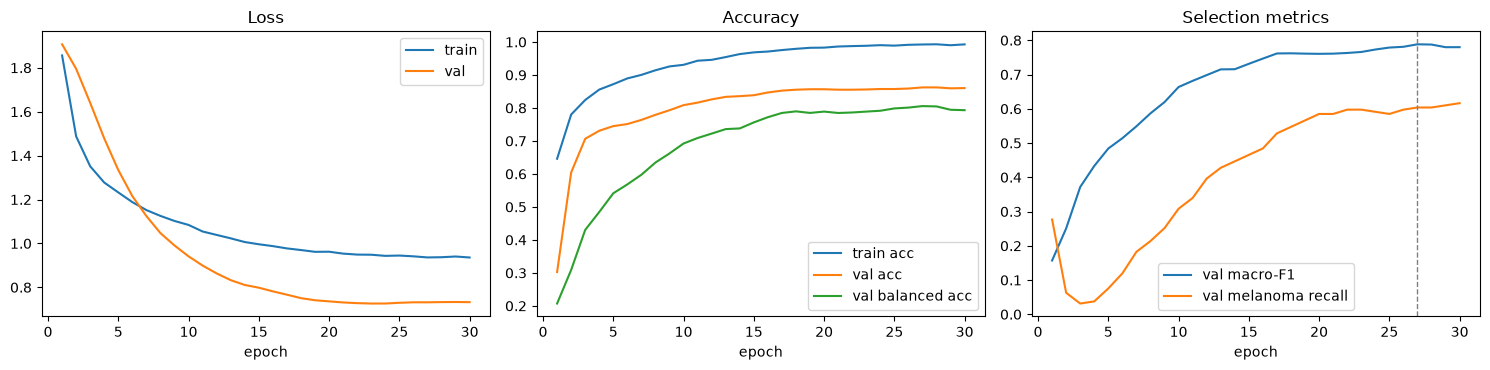

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train"); axes[0].plot(hist["epoch"], hist["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(hist["epoch"], hist["train_acc"], label="train acc"); axes[1].plot(hist["epoch"], hist["val_acc"], label="val acc")
axes[1].plot(hist["epoch"], hist["val_bal_acc"], label="val balanced acc"); axes[1].set_title("Accuracy"); axes[1].legend()
axes[2].plot(hist["epoch"], hist["val_macro_f1"], label="val macro-F1"); axes[2].plot(hist["epoch"], hist["val_mel_recall"], label="val melanoma recall")
axes[2].axvline(best_epoch, ls="--", c="gray", lw=1); axes[2].set_title("Selection metrics"); axes[2].legend()
for ax in axes: ax.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "curves.png"), dpi=110); plt.show()

## 6. Calibration (temperature scaling)

Neural networks are usually over-confident. Temperature scaling learns one number `T` on the **validation** set and divides all logits by it: `softmax(logits / T)`. The predicted class never changes, only how confident the scores are.

This is done twice: for single-view predictions (what the app does today) and for TTA predictions.

In [13]:
model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE))

def fit_temperature(logits, y):
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad()
        loss = nn.functional.cross_entropy(logits / log_t.exp().clamp(0.05, 20.0), y)
        loss.backward()
        return loss
    opt.step(closure)
    return float(log_t.exp().clamp(0.05, 20.0))

MODES = ["single"] + (["tta"] if CFG["tta"] else [])
LOGITS = {}
for mode in MODES:
    vl, vy = predict(val_loader, model, tta=(mode == "tta"))
    tl, ty = predict(test_loader, model, tta=(mode == "tta"))
    T_mode = fit_temperature(vl, vy)
    LOGITS[mode] = {"val": vl, "val_y": vy, "test": tl, "test_y": ty, "T": T_mode}
    print(f"{mode:>6}: temperature T = {T_mode:.3f}")
T = LOGITS["single"]["T"]          # the app uses single-view predictions
test_y = LOGITS["single"]["test_y"]

C:\Users\krish.LAPTOP-3EPNQNP7\AppData\Local\Temp\ipykernel_28608\4013264356.py:12: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  return float(log_t.exp().clamp(0.05, 20.0))


single: temperature T = 0.693
   tta: temperature T = 0.652


## 7. Evaluation metrics

Every metric below is computed on the **test** set (unseen lesions) from **calibrated** probabilities.

| Group | Metric | What it tells you |
|---|---|---|
| Overall | **Accuracy** | Share of images classified correctly. Inflated by the 67% nevus majority |
| | **Balanced accuracy** | Average recall across the 7 classes: every class counts equally |
| | **Top-2 / top-3 accuracy** | Is the right answer among the model's 2 or 3 best guesses? |
| | **Cohen's kappa**, **MCC** | Agreement beyond chance (0 = chance, 1 = perfect). Robust to imbalance |
| Per class | **Precision** | When the model says "melanoma", how often is it right? |
| | **Recall (sensitivity)** | Of the real melanomas, how many were caught? The key safety number |
| | **Specificity** | Of the non-melanomas, how many were correctly not called melanoma? |
| | **F1** | Balance of precision and recall. **Macro-F1** averages it over classes |
| Ranking | **ROC-AUC**, **PR-AUC** | How well scores separate a class from the rest, across all thresholds. PR-AUC is more honest for rare classes |
| Probabilities | **Log loss** | Penalises confident wrong answers heavily |
| | **Brier score** and **probability RMSE** | Mean squared distance between the predicted probabilities and the true one-hot answer, and its square root. The classification counterpart of RMSE |
| | **Pseudo-R² (McFadden)** | `1 − log-loss(model) / log-loss(training class frequencies only)`. The classification counterpart of R²: 0 = no better than knowing the class mix, 1 = perfect |
| | **ECE** | Gap between confidence and actual accuracy. Lower is better |
| Confidence | **Mean confidence** when right vs when wrong, and **accuracy at each confidence threshold** | Whether low confidence really flags uncertain cases (useful for an "inconclusive" result in the app) |

Plain **RMSE and R²** are regression metrics for predicting numbers; on class labels they would be meaningless, so their probability-based counterparts are used instead.

95% ranges come from a **lesion-level bootstrap**: test lesions are resampled 1,000 times and the metric recomputed. Wide ranges on small classes (df, vasc) are expected.

In [14]:
from sklearn.metrics import (cohen_kappa_score, matthews_corrcoef, log_loss, average_precision_score,
                             top_k_accuracy_score)

def ece_score(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1); total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any():
            total += mk.mean() * abs(conf[mk].mean() - correct[mk].mean())
    return float(total)

def evaluate(probs, y_true):
    y_pred = probs.argmax(1)
    labels = list(range(N_CLASSES))
    onehot = np.eye(N_CLASSES)[y_true]
    prior = np.bincount(train_df["label"].values, minlength=N_CLASSES) + 1.0   # training class mix (+1 smoothing)
    prior = prior / prior.sum()
    ll = log_loss(y_true, probs, labels=labels)
    ll_null = log_loss(y_true, np.tile(prior, (len(y_true), 1)), labels=labels)
    brier = float(((probs - onehot) ** 2).sum(1).mean())
    conf = probs.max(1); right = y_pred == y_true
    overall = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "top2_accuracy": top_k_accuracy_score(y_true, probs, k=2, labels=labels),
        "top3_accuracy": top_k_accuracy_score(y_true, probs, k=3, labels=labels),
        "macro_precision": precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)[0],
        "macro_recall": precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)[1],
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "log_loss": ll,
        "brier_score": brier,
        "probability_rmse": float(np.sqrt(((probs - onehot) ** 2).mean())),
        "pseudo_r2_mcfadden": 1 - ll / ll_null,
        "ece": ece_score(probs, y_true),
        "mean_confidence": float(conf.mean()),
        "mean_confidence_correct": float(conf[right].mean()) if right.any() else float("nan"),
        "mean_confidence_wrong": float(conf[~right].mean()) if (~right).any() else float("nan"),
    }
    prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    spec, auc, ap = [], [], []
    for k in labels:
        tn = cm.sum() - cm[k, :].sum() - cm[:, k].sum() + cm[k, k]
        spec.append(tn / max(1, cm.sum() - cm[k, :].sum()))
        yk = (y_true == k).astype(int)
        auc.append(roc_auc_score(yk, probs[:, k]) if 0 < yk.sum() < len(yk) else np.nan)
        ap.append(average_precision_score(yk, probs[:, k]) if yk.sum() > 0 else np.nan)
    overall["macro_roc_auc"] = float(np.nanmean(auc)); overall["macro_pr_auc"] = float(np.nanmean(ap))
    overall["melanoma_recall"] = rec[MEL]; overall["melanoma_specificity"] = spec[MEL]; overall["melanoma_precision"] = prec[MEL]
    per_class = pd.DataFrame({"precision": prec, "recall": rec, "specificity": spec, "F1": f1,
                              "ROC-AUC": auc, "PR-AUC": ap, "test images": sup}, index=CLASSES)
    return overall, per_class, cm, y_pred

RESULTS = {}
for mode in MODES:
    probs = (LOGITS[mode]["test"] / LOGITS[mode]["T"]).softmax(1).numpy()
    RESULTS[mode] = dict(zip(["overall", "per_class", "cm", "y_pred"], evaluate(probs, test_y.numpy())))
    RESULTS[mode]["probs"] = probs

y_true = test_y.numpy()
baseline = float((y_true == CLASSES.index("NV")).mean())
table = pd.DataFrame({m: RESULTS[m]["overall"] for m in MODES}).round(4)
table.columns = ["single view (app)" if c == "single" else "TTA (8 views)" for c in table.columns]
print(f"Always-'NV' baseline accuracy on this test set: {baseline:.4f}")
display(table)

Always-'NV' baseline accuracy on this test set: 0.6695


,single view (app),TTA (8 views)
accuracy,0.8519,0.8595
balanced_accuracy,0.6880,0.6983
top2_accuracy,0.9133,0.9224
top3_accuracy,0.9322,0.9385
macro_precision,0.7666,0.7962
macro_recall,0.6880,0.6983
macro_f1,0.7146,0.7275
weighted_f1,0.8471,0.8537
cohen_kappa,0.7067,0.7195
mcc,0.7086,0.7223


In [15]:
# 95% ranges (lesion-level bootstrap) and the per-class table, for the mode the app uses
REPORT_MODE = "single"
y_pred = RESULTS[REPORT_MODE]["y_pred"]
rng = np.random.default_rng(CFG["seed"])
lesions = test_df["lesion_id"].values
groups = {l: np.where(lesions == l)[0] for l in np.unique(lesions)}
keys = list(groups)
def mel_recall(t, p): return ((p == MEL) & (t == MEL)).sum() / max(1, (t == MEL).sum())
def boot(metric_fn, n=1000):
    vals = []
    for _ in range(n):
        idx = np.concatenate([groups[k] for k in rng.choice(keys, len(keys), replace=True)])
        vals.append(metric_fn(y_true[idx], y_pred[idx]))
    return np.percentile(vals, [2.5, 97.5])

ci = {
    "accuracy": boot(accuracy_score),
    "balanced_accuracy": boot(balanced_accuracy_score),
    "macro_f1": boot(lambda t, p: f1_score(t, p, average="macro", zero_division=0)),
    "melanoma_recall": boot(mel_recall),
}
ov = RESULTS[REPORT_MODE]["overall"]
print("Key test metrics (single view, calibrated) with 95% ranges:")
for k, (lo, hi) in ci.items():
    print(f"  {k:>18}: {ov[k]:.3f}   ({lo:.3f} – {hi:.3f})")

per_class = RESULTS[REPORT_MODE]["per_class"].round(3)
display(per_class)

Key test metrics (single view, calibrated) with 95% ranges:
            accuracy: 0.852   (0.828 – 0.874)
   balanced_accuracy: 0.688   (0.626 – 0.757)
            macro_f1: 0.715   (0.641 – 0.772)
     melanoma_recall: 0.566   (0.473 – 0.667)


,precision,recall,specificity,F1,ROC-AUC,PR-AUC,test images
AKIEC,0.571,0.696,0.983,0.627,0.835,0.526,46
BCC,0.723,0.811,0.983,0.764,0.983,0.808,74
BKL,0.797,0.624,0.980,0.700,0.892,0.689,157
DF,0.778,0.412,0.999,0.538,0.833,0.596,17
MEL,0.647,0.566,0.961,0.604,0.901,0.654,159
NV,0.912,0.957,0.814,0.934,0.932,0.944,958
VASC,0.938,0.750,0.999,0.833,0.963,0.842,20


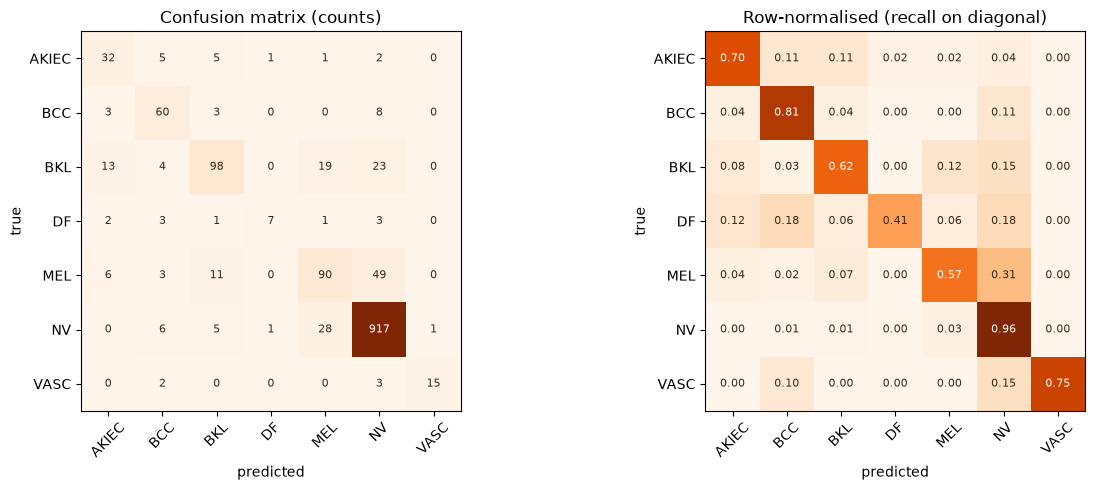

Melanomas the model missed, by what it called them: {'AKIEC': 6, 'BCC': 3, 'BKL': 11, 'NV': 49}


In [16]:
cm = RESULTS[REPORT_MODE]["cm"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm_norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
for ax, mat, title, fmt in [(axes[0], cm, "Confusion matrix (counts)", "d"), (axes[1], cm_norm, "Row-normalised (recall on diagonal)", ".2f")]:
    ax.imshow(mat, cmap="Oranges")
    ax.set_xticks(range(N_CLASSES), CLASSES, rotation=45); ax.set_yticks(range(N_CLASSES), CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            v = mat[i, j]
            ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=8,
                    color="white" if v > mat.max() * 0.55 else "#3a2a1a")
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "confusion_matrix.png"), dpi=110); plt.show()

mel_missed = cm[MEL].copy(); mel_missed[MEL] = 0
print("Melanomas the model missed, by what it called them:", {CLASSES[j]: int(n) for j, n in enumerate(mel_missed) if n})

### Confidence analysis

Left: reliability before and after temperature scaling (on the diagonal = honest confidence). Middle: how confident the model is when it is right vs wrong. Right/table: if the app only showed a result when confidence is above a threshold, how many images would get an answer (coverage) and how accurate those answers would be. This is how to choose a cut-off for an "inconclusive" result.

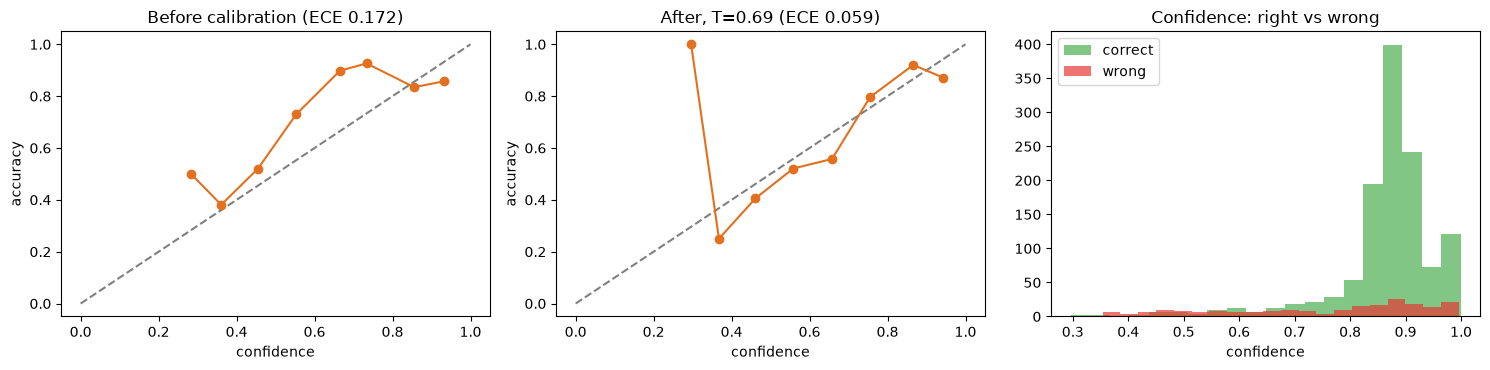

,min confidence,coverage,accuracy on answered,melanoma recall on answered
0,0.0,1.000,0.852,0.566
1,0.4,0.991,0.857,0.573
2,0.5,0.965,0.869,0.588
3,0.6,0.932,0.881,0.601
4,0.7,0.895,0.895,0.638
5,0.8,0.823,0.903,0.632
6,0.9,0.288,0.871,0.833


In [17]:
p_raw = LOGITS["single"]["test"].softmax(1).numpy()
p_cal = RESULTS["single"]["probs"]

def reliability(ax, probs, title):
    conf, pred = probs.max(1), probs.argmax(1); correct = (pred == y_true).astype(float)
    edges = np.linspace(0, 1, 11); mids, accs = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.sum() > 0:
            mids.append(conf[mk].mean()); accs.append(correct[mk].mean())
    ax.plot([0, 1], [0, 1], "--", c="gray"); ax.plot(mids, accs, "o-", c="#e2701f")
    ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.set_title(title)

conf = p_cal.max(1); right = p_cal.argmax(1) == y_true
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
reliability(axes[0], p_raw, f"Before calibration (ECE {ece_score(p_raw, y_true):.3f})")
reliability(axes[1], p_cal, f"After, T={T:.2f} (ECE {ece_score(p_cal, y_true):.3f})")
axes[2].hist(conf[right], bins=20, alpha=0.7, label="correct", color="#4caf50")
axes[2].hist(conf[~right], bins=20, alpha=0.7, label="wrong", color="#e53935")
axes[2].set_xlabel("confidence"); axes[2].set_title("Confidence: right vs wrong"); axes[2].legend()
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "calibration.png"), dpi=110); plt.show()

rows = []
for t in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = conf >= t
    rows.append({"min confidence": t, "coverage": keep.mean(),
                 "accuracy on answered": accuracy_score(y_true[keep], p_cal.argmax(1)[keep]) if keep.any() else np.nan,
                 "melanoma recall on answered": mel_recall(y_true[keep], p_cal.argmax(1)[keep]) if keep.any() else np.nan})
coverage = pd.DataFrame(rows).round(3)
display(coverage)

## 8. Grad-CAM check

A quick look at where the model reacts, on correct and incorrect test predictions. Look for attention on the lesion rather than on corners, rulers or ink marks. Same method as the app: gradients of the class score at the last ResNet block.

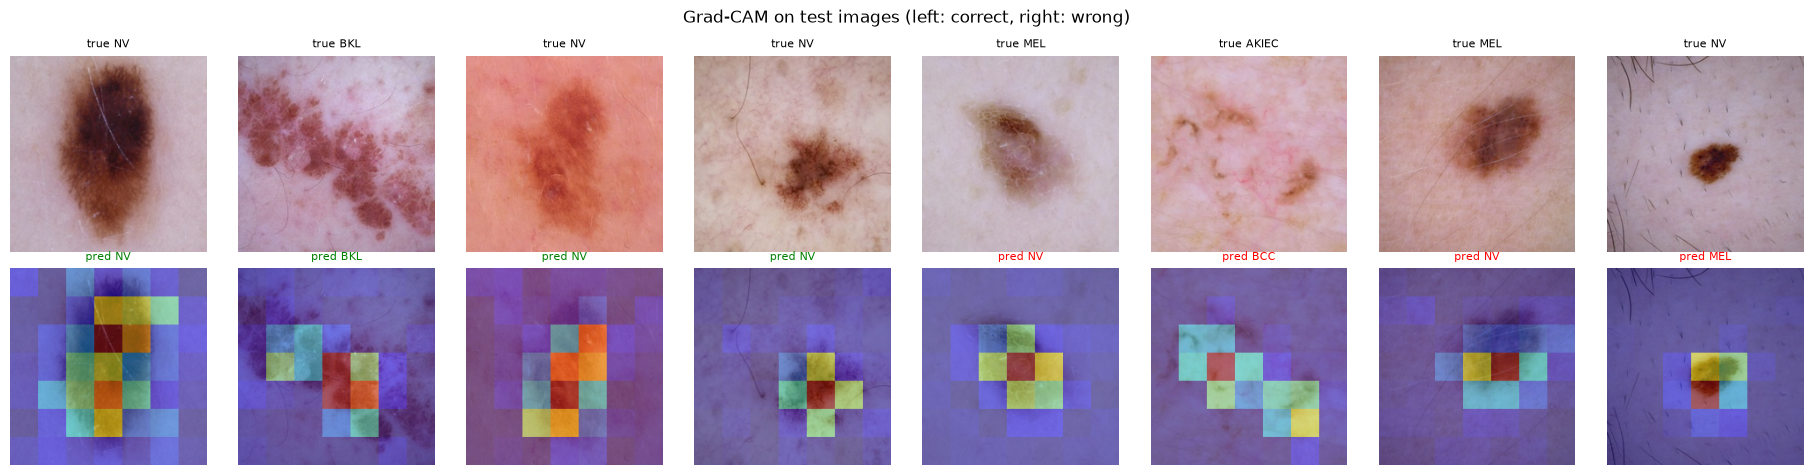

In [18]:
backbone = model if EXPERIMENT == "image" else model.backbone
target_layer = backbone.layer4[-1]
store = {}
h1 = target_layer.register_forward_hook(lambda mod, i, o: store.__setitem__("act", o))
h2 = target_layer.register_full_backward_hook(lambda mod, gi, go: store.__setitem__("grad", go[0]))

def gradcam(x, m, cls):
    model.eval(); model.zero_grad(set_to_none=True)
    logits = U.forward(model, EXPERIMENT, x.unsqueeze(0).to(DEVICE), m.unsqueeze(0).to(DEVICE))
    logits[0, cls].backward()
    w = store["grad"][0].mean(dim=(1, 2))
    cam = torch.relu((w[:, None, None] * store["act"][0]).sum(0)).detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

right_idx = np.where(y_pred == y_true)[0]; wrong_idx = np.where(y_pred != y_true)[0]
pick = list(rng.choice(right_idx, min(4, len(right_idx)), replace=False)) + list(rng.choice(wrong_idx, min(4, len(wrong_idx)), replace=False))
fig, axes = plt.subplots(2, len(pick), figsize=(2.3 * len(pick), 4.8), squeeze=False)
for c, i in enumerate(pick):
    x, m, y = test_ds[i]
    img = np.clip(x.permute(1, 2, 0).numpy() * std + mean, 0, 1)
    cam = gradcam(x, m, int(y_pred[i]))
    cam_big = np.array(plt.cm.jet(np.kron(cam, np.ones((32, 32))))[..., :3])
    axes[0, c].imshow(img); axes[0, c].set_title(f"true {CLASSES[y]}", fontsize=8)
    axes[1, c].imshow(0.55 * img + 0.45 * cam_big)
    axes[1, c].set_title(f"pred {CLASSES[y_pred[i]]}", fontsize=8, color="green" if y_pred[i] == y else "red")
    axes[0, c].axis("off"); axes[1, c].axis("off")
plt.suptitle("Grad-CAM on test images (left: correct, right: wrong)"); plt.tight_layout()
plt.savefig(os.path.join(RUN_DIR, "gradcam_examples.png"), dpi=110); plt.show()
h1.remove(); h2.remove()

## 9. Save everything the backend needs

For `EXPERIMENT = "image"`, copy these into `gradia-backend/weights/`:

- `resnet50_ham10000.pth` (replaces the old one; same architecture, so `inference.py` loads it unchanged)
- `classes.json` (the backend already reads this if present)
- `calibration.json` (temperature for single-view predictions; the backend needs a small update to use it)

`metrics.json` holds every number above, for the README and for interviews.

In [19]:
state = torch.load(BEST_PATH, map_location="cpu")
weights_name = "resnet50_ham10000.pth" if EXPERIMENT == "image" else "resnet50_fusion_ham10000.pth"
torch.save(state, os.path.join(RUN_DIR, weights_name))
json.dump(CLASSES, open(os.path.join(RUN_DIR, "classes.json"), "w"))
json.dump({"temperature": T, "temperature_tta": LOGITS.get("tta", {}).get("T")},
          open(os.path.join(RUN_DIR, "calibration.json"), "w"))
json.dump({"kind": EXPERIMENT, "n_meta": N_META, "n_classes": N_CLASSES,
           "preprocess": {"resize_short": CFG["resize_short"], "center_crop": CFG["image_size"],
                          "mean": U.IMAGENET_MEAN, "std": U.IMAGENET_STD},
           "metadata_vocab": VOCAB if use_meta else None}, open(os.path.join(RUN_DIR, "model_config.json"), "w"), indent=2)

metrics = {
    "experiment": EXPERIMENT, "best_epoch": best_epoch, f"best_val_{SEL}": best_score, "temperature": T,
    "test_baseline_always_nv": baseline,
    "test": {m: {k: float(v) for k, v in RESULTS[m]["overall"].items()} for m in MODES},
    "test_95ci_single": {k: [float(a), float(b)] for k, (a, b) in ci.items()},
    "test_per_class_single": per_class.reset_index().rename(columns={"index": "class"}).to_dict(orient="records"),
    "confidence_coverage_single": coverage.to_dict(orient="records"),
    "config": CFG,
}
json.dump(metrics, open(os.path.join(RUN_DIR, "metrics.json"), "w"), indent=2, default=float)
print("Saved to", RUN_DIR)
for f in sorted(os.listdir(RUN_DIR)): print("  ", f)

Saved to C:\Users\krish.LAPTOP-3EPNQNP7\Documents\gradia_data\runs\image
   augmented_samples.png
   best.pth
   calibration.json
   calibration.png
   classes.json
   confusion_matrix.png
   curves.png
   gradcam_examples.png
   history.csv
   metrics.json
   model_config.json
   resnet50_ham10000.pth


## 10. Compare experiments

Run the notebook once with `"image"` and once with `"fusion"`, then this cell shows them side by side (single-view numbers).

In [20]:
rows = {}
for exp in ["image", "fusion"]:
    p = os.path.join(DATA_DIR, "runs", exp, "metrics.json")
    if os.path.exists(p):
        mtr = json.load(open(p))
        t = mtr["test"]["single"]
        rows[exp] = {k: round(t[k], 3) for k in ["accuracy", "balanced_accuracy", "macro_f1", "melanoma_recall",
                                                 "macro_roc_auc", "cohen_kappa", "pseudo_r2_mcfadden", "probability_rmse", "ece"]}
        rows[exp]["macro_f1 95% range"] = "–".join(f"{v:.3f}" for v in mtr["test_95ci_single"]["macro_f1"])
        rows[exp]["best epoch"] = mtr["best_epoch"]
display(pd.DataFrame(rows))
if len(rows) == 2:
    d = rows["fusion"]["macro_f1"] - rows["image"]["macro_f1"]
    print(f"Fusion changes test macro-F1 by {d:+.3f}. If the 95% ranges overlap heavily, the difference may not be real.")

,image
accuracy,0.852
balanced_accuracy,0.688
macro_f1,0.715
melanoma_recall,0.566
macro_roc_auc,0.905
cohen_kappa,0.707
pseudo_r2_mcfadden,0.432
probability_rmse,0.188
ece,0.059
macro_f1 95% range,0.641–0.772
